In [1]:
import torch
import torch.distributions as dist
import neml2
from collections import defaultdict
from pyzag import stochastic, nonlinear, reparametrization, chunktime
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import os
import re
import copy
import tqdm
import pandas as pd
from neml2.cli.inspect import main as inspect_main
import math
import pyro
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoDelta
from pyro.optim import ClippedAdam

In [2]:
torch.manual_seed(0)

torch.set_default_dtype(torch.double)
if torch.cuda.is_available():
    dev = "cuda:0"
    print("CUDA is available")
    print(f"CUDA version: {torch.version.cuda}")
else:
    dev = "cpu"
device = torch.device(dev)

In [3]:
class SolveStrain(torch.nn.Module):
    """Just integrate the model through some strain history

    Args:
        discrete_equations: the pyzag wrapped model
        nchunk (int): number of vectorized time steps
        rtol (float): relative tolerance to use for Newton's method during time integration
        atol (float): absolute tolerance to use for Newton's method during time integration
    """

    def __init__(self, discrete_equations, nchunk=1, rtol=1.0e-6, atol=1.0e-4, initial_rho_m=4.51):
        super().__init__()
        self.discrete_equations = discrete_equations
        self.nchunk = nchunk
        self.cached_solution = None
        self.rtol = rtol
        self.atol = atol
        self.initial_rho_m = initial_rho_m

    def forward(self, loading, time, temperature, cache=False):
        """Integrate through some time/temperature/strain history and return stress
        Args:
            time (torch.tensor): batched times
            temperature (torch.tensor): batched temperatures
            loading (torch.tensor): loading conditions, which are the input strain in the first base index and then the stress (zero) in the remainder

        Keyword Args:
            cache (bool): if true, cache the solution and use it as a predictor for the next call.
                This heuristic can speed things up during inference where the model is called repeatedly with similar parameter values.
        """
        newton = chunktime.ChunkNewtonRaphsonLineSearch(
            rtol=self.rtol,
            atol=self.atol,
            throw_on_fail=False,
            record_failed=True,
            linesearch_iter=8,
        )
        if cache and self.cached_solution is not None:
            solver = nonlinear.RecursiveNonlinearEquationSolver(
                self.discrete_equations,
                step_generator=nonlinear.StepGenerator(self.nchunk),
                predictor=nonlinear.FullTrajectoryPredictor(self.cached_solution),  # type: ignore
                nonlinear_solver=newton,
            )
        else:
            solver = nonlinear.RecursiveNonlinearEquationSolver(
                self.discrete_equations,
                step_generator=nonlinear.StepGenerator(self.nchunk),
                predictor=nonlinear.PreviousStepsPredictor(),  # type: ignore
                nonlinear_solver=newton,
            )

        control = torch.zeros_like(loading)
        control[..., 1:] = 1.0

        # Pack the per-force raw tensors into the single flat forces tensor
        # pyzag consumes. ``assemble_forces`` uses the adapter's own force
        # layout, so the packing is guaranteed to match how the factory later
        # splits the tensor back apart (``_split_by_layout``); base sizes come
        # from the layout, so scalars need no trailing-1 unsqueeze here.
        forces = self.discrete_equations.assemble_forces(
            {
                "fixed_values": loading,
                "t": time,
                "temperature": temperature,
                "control": control,
            }
        )
        state0 = self.discrete_equations.assemble_state(
            {
                "mixed_state": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
                "log_rho_m": torch.full(
                    forces.shape[1:-1], math.log(self.initial_rho_m), device=forces.device
                ),
                "back_stress": torch.zeros(forces.shape[1:-1] + (6,), device=forces.device),
            }
        )

        result = nonlinear.solve_adjoint(solver, state0, len(forces), forces)

        if cache:
            self.cached_solution = result.detach().clone()

        if not torch.isfinite(result).all():
            raise RuntimeError(
                "Non-finite state in the integrated solution: the solve produced NaN/Inf "
                "that pyzag's convergence test did not catch. Reduce nchunk or the step size."
            )

        return result[..., 0:1]

    def density(self, result):
        """Physical mobile dislocation density (um^{-2}) from a solved trajectory."""
        return torch.exp(result[..., 6:7])

In [4]:
nmodel = neml2.load_nonlinear_system("tungsten.i", "eq_sys")
nmodel.to(device=device)
pmodel = neml2.pyzag.NEML2PyzagModel(
    nmodel,
    include_parameters=[
        "v_disl_B_k",
        "v_disl_T_0",
        "v_disl_p",
        "v_disl_q",
        "v_disl_H_0",
        "rho_m_rate_k1",
        "rho_m_rate_k2_0",
        "rho_m_rate_Q_d",
        "kinharden_C",
        "kinharden_g",
    ],
)
neml2.compile(pmodel)

model = SolveStrain(pmodel, nchunk=50)
_ = inspect_main(["tungsten.i", "implicit_rate"])

Model: ComposedModel

Inputs (13):
  log_rho_m: type=Scalar
  control: type=SR2
  fixed_values: type=SR2
  mixed_state: type=SR2
  control~1: type=SR2
  fixed_values~1: type=SR2
  mixed_state~1: type=SR2
  temperature: type=Scalar
  t: type=Scalar
  t~1: type=Scalar
  back_stress: type=SR2
  back_stress~1: type=SR2
  log_rho_m~1: type=Scalar

Outputs (3):
  back_stress_residual: type=SR2
  log_rho_m_residual: type=Scalar
  stress_residual: type=SR2

Parameters (50):
  rho_m_from_log.scaling: dtype=torch.float64, device=cpu, shape=[]
  rho_m_from_log.rate: dtype=torch.float64, device=cpu, shape=[]
  E.a: dtype=torch.float64, device=cpu, shape=[]
  E.b: dtype=torch.float64, device=cpu, shape=[]
  E.c: dtype=torch.float64, device=cpu, shape=[]
  nu.a: dtype=torch.float64, device=cpu, shape=[]
  nu.b: dtype=torch.float64, device=cpu, shape=[]
  nu.c: dtype=torch.float64, device=cpu, shape=[]
  L.c_lath: dtype=torch.float64, device=cpu, shape=[]
  L.d_lath: dtype=torch.float64, device=cpu, 

0.42%: 37 points, loop uses 29 (strain -0.420% to 0.420%)
0.58%: 45 points, loop uses 34 (strain -0.587% to 0.582%)
0.75%: 47 points, loop uses 32 (strain -0.756% to 0.749%)


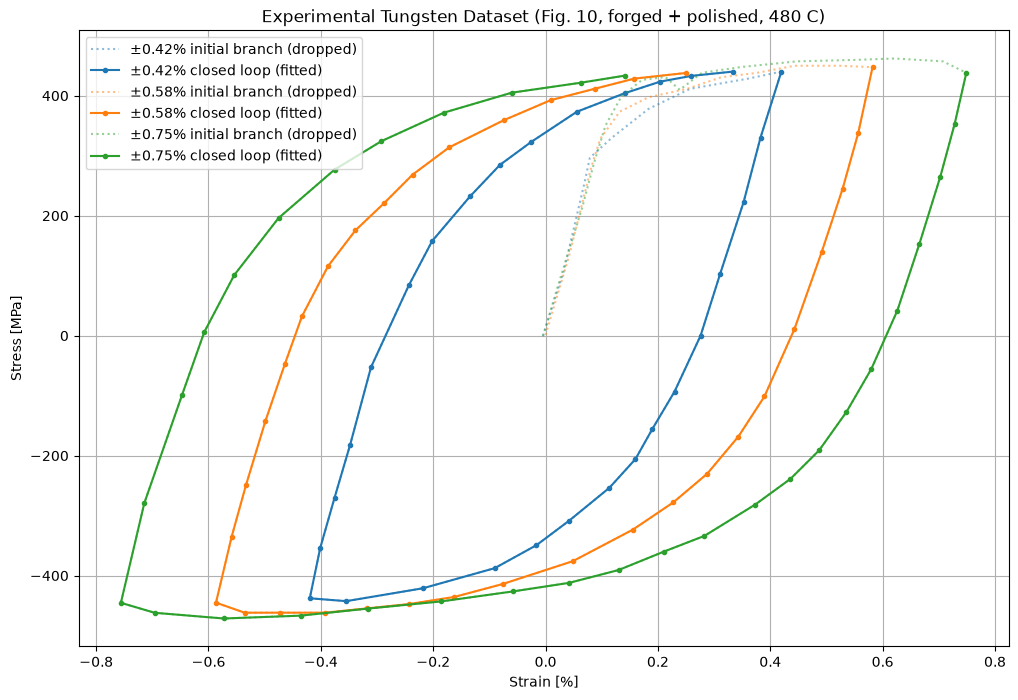

In [5]:
# Digitized Fig. 10 of Habainy et al. (2015): forged + polished W at 480 C, MST test.
# Columns: x = engineering strain [%], y = engineering stress [MPa].
path = "cyclic_data"
amp_labels = ["0.42", "0.58", "0.75"]

raw_strain = {}  # full digitized curve, strain as a fraction
raw_stress = {}
loop_strain = {}  # closed hysteresis loop only, starting at the +peak
loop_stress = {}

for label in amp_labels:
    (filename,) = [f for f in os.listdir(path) if f.endswith(".csv") and label in f]
    df = pd.read_csv(os.path.join(path, filename))
    # No re-zeroing: the digitized loops are already symmetric about zero strain, and
    # subtracting the first point (a ~0.005% digitizer offset) would shift the whole loop.
    strain = torch.tensor(df["x"].values, device=device) * 1.0e-2  # % -> fraction
    stress = torch.tensor(df["y"].values, device=device)
    raw_strain[label] = strain
    raw_stress[label] = stress

    # The branch rising from (0, 0) is the monotonic first loading drawn under every loop
    # (it lies on the tensile curve in Fig. 10); it is not part of that level's cyclic
    # history. Keep only the closed loop: +peak -> -peak -> back up.
    i_peak = int(torch.argmax(strain))
    loop_strain[label] = strain[i_peak:]
    loop_stress[label] = stress[i_peak:]
    print(
        f"{label}%: {len(strain)} points, loop uses {len(loop_strain[label])} "
        f"(strain {loop_strain[label].min() * 100:.3f}% to {loop_strain[label].max() * 100:.3f}%)"
    )

plt.figure(figsize=(12, 8))
for j, label in enumerate(amp_labels):
    plt.plot(
        raw_strain[label].cpu().numpy() * 100,
        raw_stress[label].cpu().numpy(),
        ":",
        color=f"C{j}",
        alpha=0.5,
        label=f"±{label}% initial branch (dropped)",
    )
    plt.plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "-o",
        ms=3,
        color=f"C{j}",
        label=f"±{label}% closed loop (fitted)",
    )
plt.xlabel("Strain [%]")
plt.ylabel("Stress [MPa]")
plt.title("Experimental Tungsten Dataset (Fig. 10, forged + polished, 480 C)")
plt.grid()
plt.legend()
plt.show()

In [6]:
temperature_K = 480.0 + 273.15
strain_rate = 2.0e-3  # 1/s: 2 mm/s over the 20 mm gauge section (Fig. 1b); also try 2.0e-3

amplitudes = [0.0042, 0.0058, 0.0075]  # strain amplitudes (fraction), one per MST step
n_cycles = [20, 20, 9]  # cycles per step; the paper only fixes the last one (failure at 9)
compare_cycle = [n_cycles[0] - 1, n_cycles[1] - 1, 4]  # 0-based cycle compared in each step
loss_weights = [1.0, 1.0, 0.5]

points_per_cycle = 80  # time steps per cycle; must be a multiple of 4
assert points_per_cycle % 4 == 0

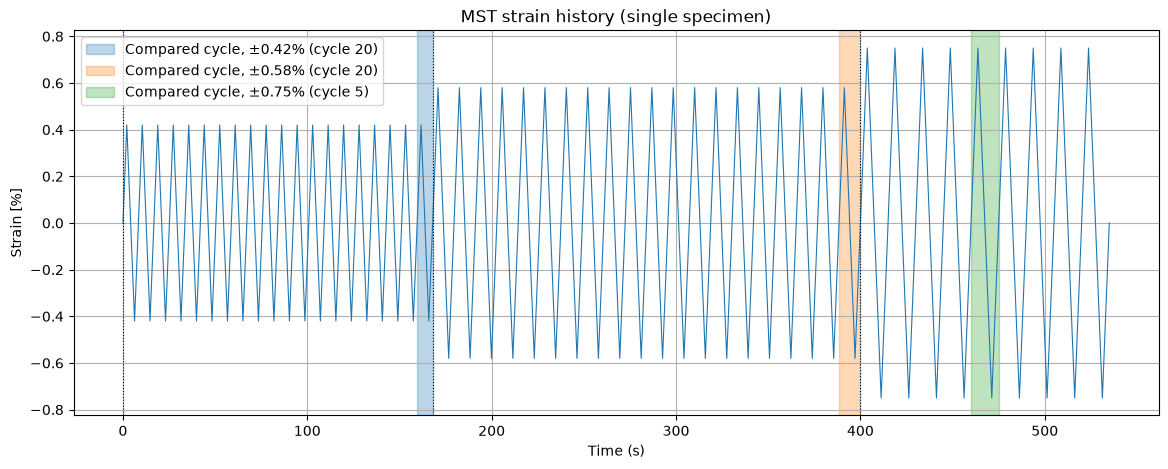


--- Full Input Tensors ---
time: torch.Size([3921, 1])
temperature: torch.Size([3921, 1])
loading: torch.Size([3921, 1, 6])


In [7]:
q = points_per_cycle // 4


def one_cycle(amp):
    """One fully reversed triangle cycle 0 -> +amp -> -amp -> 0 at constant |strain rate|."""
    return torch.cat(
        [
            torch.linspace(0.0, amp, q + 1, device=device)[1:],
            torch.linspace(amp, -amp, 2 * q + 1, device=device)[1:],
            torch.linspace(-amp, 0.0, q + 1, device=device)[1:],
        ]
    )


# Step blocks back to back; each block starts and ends at zero strain, so the history is
# continuous. block_start[j] is the time index of the first step of block j (index 0 is t = 0).
segments = []
block_start = []
n = 1
for amp, nc in zip(amplitudes, n_cycles):
    block_start.append(n)
    segments.append(one_cycle(amp).repeat(nc))
    n += len(segments[-1])

strain_history = torch.cat([torch.zeros(1, device=device)] + segments)
# Constant strain rate: time advances with the strain path length.
time_history = (
    torch.cat([torch.zeros(1, device=device), strain_history.diff().abs()]).cumsum(0) / strain_rate
)

ntime = len(strain_history)
nbatch = 1
time = time_history[:, None].clone()
temperature = torch.full_like(time, temperature_K)
loading = torch.zeros((ntime, nbatch, 6), device=device)
loading[:, 0, 0] = strain_history

plt.figure(figsize=(14, 5))
plt.plot(time_history.cpu().numpy(), strain_history.cpu().numpy() * 100, lw=0.8)
for j, start in enumerate(block_start):
    plt.axvline(time_history[start - 1].item(), color="k", ls=":", lw=0.8)
    first = start + compare_cycle[j] * points_per_cycle
    plt.axvspan(
        time_history[first - 1].item(),
        time_history[first + points_per_cycle - 1].item(),
        color=f"C{j}",
        alpha=0.3,
        label=f"Compared cycle, ±{amp_labels[j]}% (cycle {compare_cycle[j] + 1})",
    )
plt.xlabel("Time (s)")
plt.ylabel("Strain [%]")
plt.title("MST strain history (single specimen)")
plt.legend()
plt.grid()
plt.show()

print(
    f"\n--- Full Input Tensors ---\ntime: {time.shape}\ntemperature: {temperature.shape}\nloading: {loading.shape}"
)

±0.42%: 72 compared points (time steps 1540..1611)
±0.58%: 67 compared points (time steps 3140..3206)
±0.75%: 64 compared points (time steps 3540..3603)


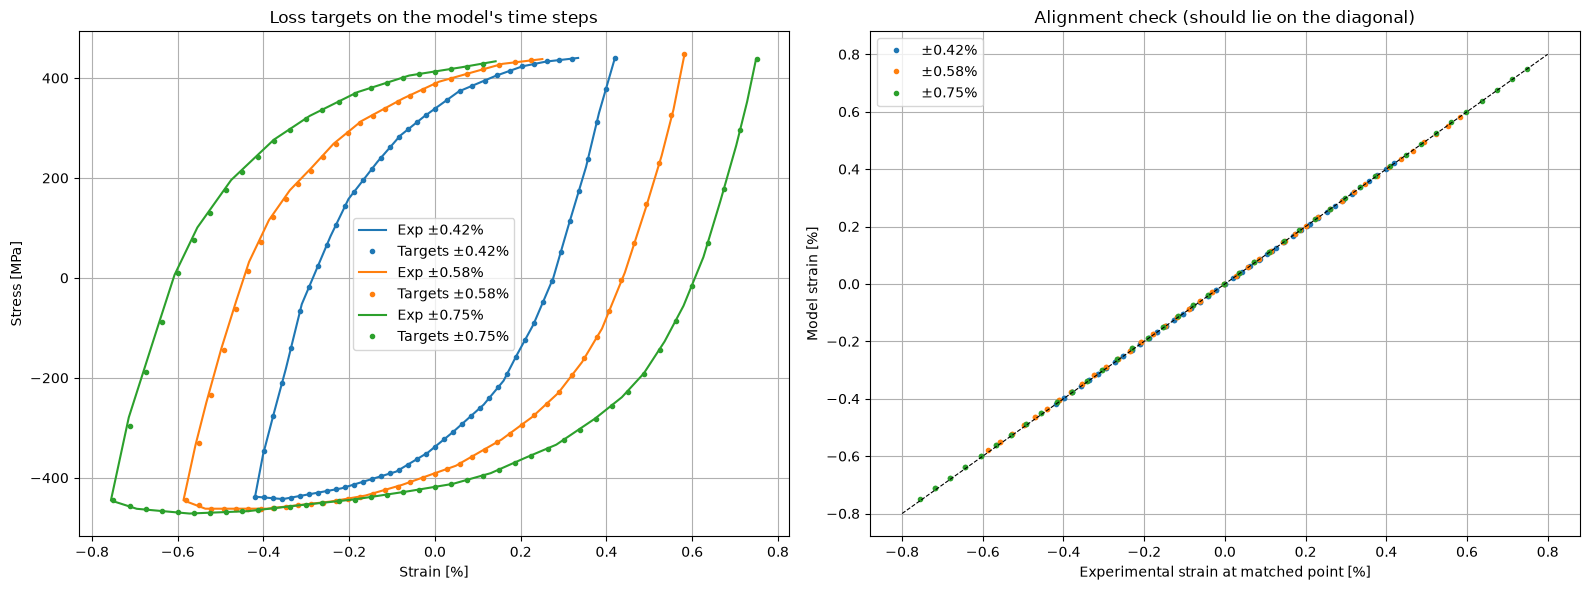

In [8]:
def loop_fraction(strain, full_loop_path):
    """Distance travelled along the strain path, as a fraction of one full loop."""
    s = torch.cat([strain.new_zeros(1), strain.diff().abs()]).cumsum(0)
    return s / full_loop_path


# For each step, take the model's compared cycle starting at its +peak and match it to the
# digitized loop by the fraction of the loop travelled, not by point index. The fraction is
# normalized by each loop's own peak-to-peak strain, so small differences between nominal
# and digitized amplitudes don't misalign the branches.
compare_idx = []  # time indices into the model history, one tensor per step
targets = []  # experimental stress at those indices
target_strain = []  # experimental strain at those indices (for plotting only)
for j, label in enumerate(amp_labels):
    i_peak = block_start[j] + compare_cycle[j] * points_per_cycle + q - 1
    window = torch.arange(i_peak, min(i_peak + points_per_cycle + 1, ntime), device=device)
    u_model = loop_fraction(strain_history[window], 4.0 * amplitudes[j])

    exp_eps = loop_strain[label]
    u_exp = loop_fraction(exp_eps, 2.0 * (exp_eps.max() - exp_eps.min()))

    keep = u_model <= u_exp[-1]  # the digitized loop stops short of closing
    compare_idx.append(window[keep])
    u = u_model[keep].cpu().numpy()
    targets.append(
        torch.tensor(
            np.interp(u, u_exp.cpu().numpy(), loop_stress[label].cpu().numpy()), device=device
        )
    )
    target_strain.append(
        torch.tensor(np.interp(u, u_exp.cpu().numpy(), exp_eps.cpu().numpy()), device=device)
    )
    print(
        f"±{label}%: {len(compare_idx[j])} compared points (time steps {i_peak}..{int(window[keep][-1])})"
    )

# Check: the targets sit on the digitized loop, and model strain matches the data strain.
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for j, label in enumerate(amp_labels):
    ax[0].plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "-",
        color=f"C{j}",
        label=f"Exp ±{label}%",
    )
    ax[0].plot(
        strain_history[compare_idx[j]].cpu().numpy() * 100,
        targets[j].cpu().numpy(),
        "o",
        ms=3,
        color=f"C{j}",
        label=f"Targets ±{label}%",
    )
    ax[1].plot(
        target_strain[j].cpu().numpy() * 100,
        strain_history[compare_idx[j]].cpu().numpy() * 100,
        "o",
        ms=3,
        color=f"C{j}",
        label=f"±{label}%",
    )
ax[0].set_xlabel("Strain [%]")
ax[0].set_ylabel("Stress [MPa]")
ax[0].set_title("Loss targets on the model's time steps")
ax[0].grid()
ax[0].legend()
lim = [-0.8, 0.8]
ax[1].plot(lim, lim, "k--", lw=0.8)
ax[1].set_xlabel("Experimental strain at matched point [%]")
ax[1].set_ylabel("Model strain [%]")
ax[1].set_title("Alignment check (should lie on the diagonal)")
ax[1].grid()
ax[1].legend()
plt.tight_layout()
plt.show()

In [9]:
initial_params = {}
print("--- Before Reparameterization ---")
with torch.no_grad():
    for n, p in model.named_parameters():
        if p.dim() == 0:
            p.data = p.data.reshape(1)
        initial_params[n] = p.data.detach().clone()
        print(f"{n}: {p.data}, {p.shape}\n")

--- Before Reparameterization ---
discrete_equations.v_disl_B_k: tensor([8.3000e-11]), torch.Size([1])

discrete_equations.v_disl_T_0: tensor([3325.5000]), torch.Size([1])

discrete_equations.v_disl_p: tensor([0.6000]), torch.Size([1])

discrete_equations.v_disl_q: tensor([1.4000]), torch.Size([1])

discrete_equations.v_disl_H_0: tensor([2.5500]), torch.Size([1])

discrete_equations.kinharden_C: tensor([19000.]), torch.Size([1])

discrete_equations.kinharden_g: tensor([125.]), torch.Size([1])

discrete_equations.rho_m_rate_k1: tensor([5250.]), torch.Size([1])

discrete_equations.rho_m_rate_k2_0: tensor([525.]), torch.Size([1])

discrete_equations.rho_m_rate_Q_d: tensor([0.0110]), torch.Size([1])



In [10]:
class LogRangeRescale(reparametrization.RangeRescale):
    """Map [0, 1] to [lb, ub] in log space, so an Adam step is a relative change."""

    def __init__(
        self,
        lb: torch.Tensor | float,
        ub: torch.Tensor | float,
        clamp: bool = True,
    ) -> None:
        super().__init__(lb, ub, clamp)
        self.lb = math.log(lb)
        self.ub = math.log(ub)
        self.clamp = clamp

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        if self.clamp:
            X = torch.clamp(X, 0, 1)

        return torch.exp(X * (self.ub - self.lb) + self.lb)

    def reverse(self, X: torch.Tensor) -> torch.Tensor:
        Y = (torch.log(X) - self.lb) / (self.ub - self.lb)

        if self.clamp:
            return torch.clamp(Y, 0, 1)

        return Y

In [11]:
Bk_scaler = LogRangeRescale(
    torch.tensor(1.0e-12, device=device), torch.tensor(1.0e-9, device=device)
)  # MPa*s
T_0_scaler = reparametrization.RangeRescale(
    torch.tensor(100.0, device=device), torch.tensor(5000.0, device=device)
)  # K
p_scaler = reparametrization.RangeRescale(
    torch.tensor(0.01, device=device), torch.tensor(5.0, device=device)
)
q_scaler = reparametrization.RangeRescale(
    torch.tensor(0.01, device=device), torch.tensor(5.0, device=device)
)
H0_scaler = reparametrization.RangeRescale(
    torch.tensor(0.1, device=device), torch.tensor(10.0, device=device)
)  # eV
C_scaler = LogRangeRescale(
    torch.tensor(100.0, device=device), torch.tensor(1.0e6, device=device)
)  # MPa
g_scaler = LogRangeRescale(torch.tensor(0.1, device=device), torch.tensor(1.0e4, device=device))
k1_scaler = LogRangeRescale(
    torch.tensor(1000.0, device=device), torch.tensor(1.0e7, device=device)
)  # um^-1
k2_0_scaler = LogRangeRescale(torch.tensor(0.01, device=device), torch.tensor(1.0e6, device=device))
Q_d_scaler = LogRangeRescale(
    torch.tensor(0.0001, device=device), torch.tensor(1.0, device=device)
)  # eV

model_reparameterizer = reparametrization.Reparameterizer(
    {
        "discrete_equations.v_disl_B_k": Bk_scaler,
        "discrete_equations.v_disl_T_0": T_0_scaler,
        "discrete_equations.v_disl_p": p_scaler,
        "discrete_equations.v_disl_q": q_scaler,
        "discrete_equations.v_disl_H_0": H0_scaler,
        "discrete_equations.kinharden_C": C_scaler,
        "discrete_equations.kinharden_g": g_scaler,
        "discrete_equations.rho_m_rate_k1": k1_scaler,
        "discrete_equations.rho_m_rate_k2_0": k2_0_scaler,
        "discrete_equations.rho_m_rate_Q_d": Q_d_scaler,
    },
    error_not_provided=True,
)
model_reparameterizer(model)
print(f"--- After Reparameterization ---")
initial_params_reparam = {}
for n, p in model.named_parameters():
    initial_params_reparam[n] = p.data.detach().clone()
    print(f"{n}: {p.data}, requires_grad={p.requires_grad}")

--- After Reparameterization ---
discrete_equations.parametrizations.v_disl_B_k.original: tensor([0.6397]), requires_grad=True
discrete_equations.parametrizations.v_disl_T_0.original: tensor([0.6583]), requires_grad=True
discrete_equations.parametrizations.v_disl_p.original: tensor([0.1182]), requires_grad=True
discrete_equations.parametrizations.v_disl_q.original: tensor([0.2786]), requires_grad=True
discrete_equations.parametrizations.v_disl_H_0.original: tensor([0.2475]), requires_grad=True
discrete_equations.parametrizations.kinharden_C.original: tensor([0.5697]), requires_grad=True
discrete_equations.parametrizations.kinharden_g.original: tensor([0.6194]), requires_grad=True
discrete_equations.parametrizations.rho_m_rate_k1.original: tensor([0.1800]), requires_grad=True
discrete_equations.parametrizations.rho_m_rate_k2_0.original: tensor([0.5900]), requires_grad=True
discrete_equations.parametrizations.rho_m_rate_Q_d.original: tensor([0.5103]), requires_grad=True


In [12]:
prior_cov = 0.05
prior_noise_scale = 10.0

mapper = stochastic.MapNormal(prior_cov)
hsmodel = stochastic.HierarchicalStatisticalModel(
    model, mapper, torch.tensor(prior_noise_scale, device=device)
)

In [13]:
nreps = 10
predict = Predictive(hsmodel, num_samples=nreps)
with torch.no_grad():
    untrained = predict(loading, time, temperature)["obs"]

/var/folders/2p/krlq959x6hd3m3plq8gw7sqm0000gn/T/ipykernel_78410/1975774645.py:46: UserWarning: pyzag lowered torch._functorch.config.donated_buffer's default to False process-wide. AOTAutograd 'donated buffers' (torch>=2.12) are incompatible with pyzag's retain_graph=True adjoint over torch.compile'd models, which otherwise raises 'compiled with non-empty donated buffers'. To keep donated buffers enabled, restore torch._functorch.config._config['donated_buffer'].default = True -- compiled models differentiated through the adjoint will then error.
  solver = nonlinear.RecursiveNonlinearEquationSolver(


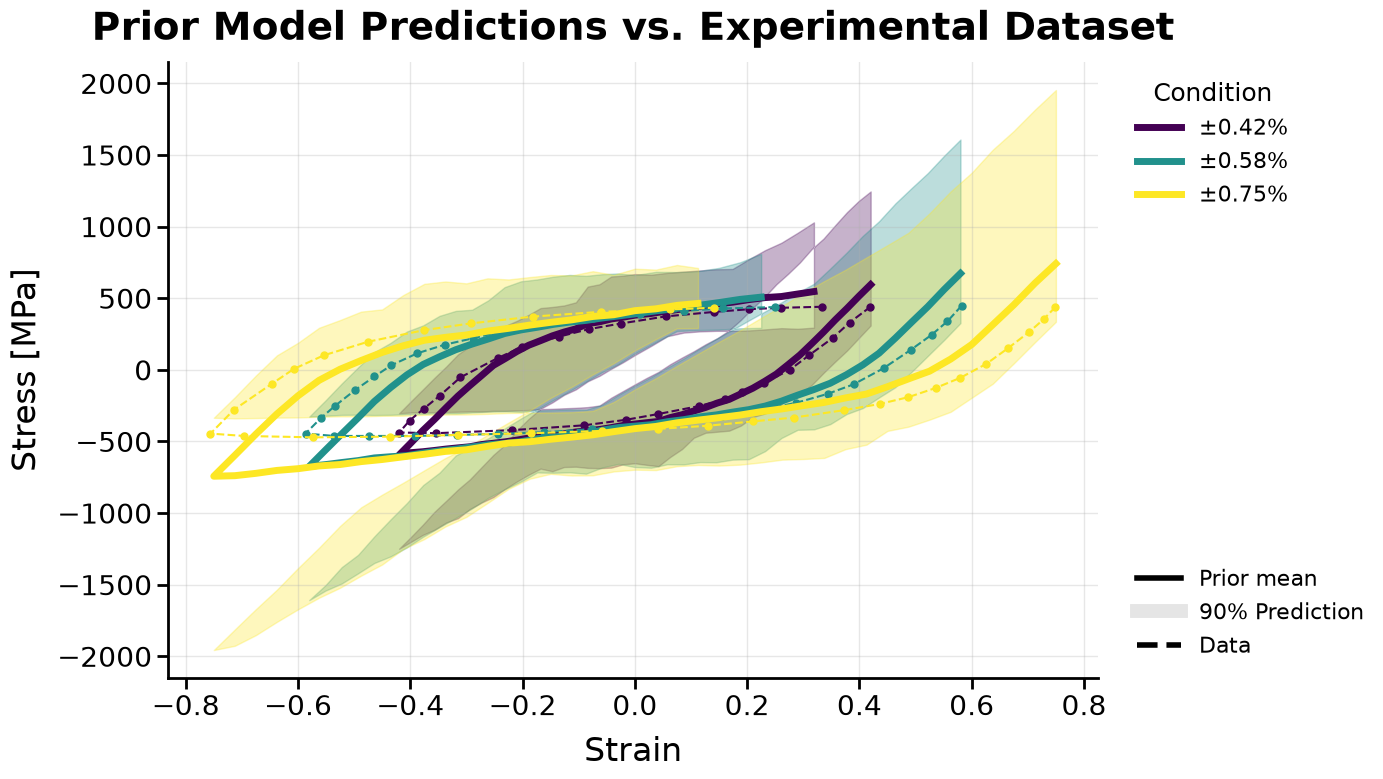

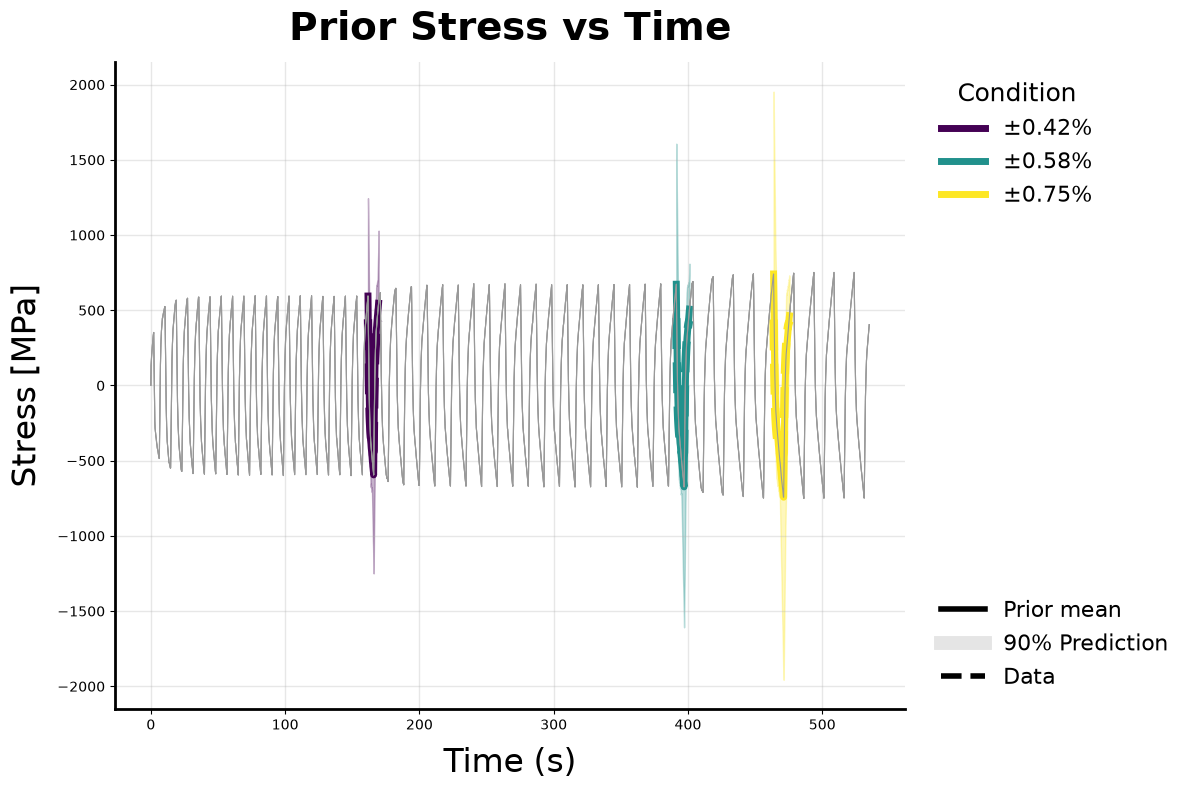

In [ ]:
color = mpl.cm.viridis(np.linspace(0, 1, len(amp_labels)))
fig, ax = plt.subplots(figsize=(12, 8))

for j, label in enumerate(amp_labels):
    prior_loop_stress = untrained[:, compare_idx[j], 0, 0]
    eps = strain_history[compare_idx[j]].cpu().numpy() * 100
    ax.plot(
        eps,
        prior_loop_stress.mean(axis=0).cpu(),
        color=color[j],
        lw=5,
    )
    lo, hi = torch.quantile(prior_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax.fill_between(
        eps,
        lo.cpu(),
        hi.cpu(),
        color=color[j],
        alpha=0.3,
    )
    ax.plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "--o",
        ms=5,
        color=color[j],
    )
# Legend: one colored entry per test condition, plus line-style key for Model vs Data
cond_handles = [
    Line2D(
        [0],
        [0],
        color=color[j],
        lw=5,
        label=rf"$\pm${amp}%",
    )
    for j, amp in enumerate(amp_labels)
]
style_handles = [
    Line2D([0], [0], color="k", lw=4, label="Prior mean"),
    Line2D([], [], color="0.8", alpha=0.5, lw=10, label="90% Prediction"),
    Line2D([0], [0], color="k", lw=4, ls="--", label="Data"),
]
leg_cond = ax.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax.add_artist(leg_cond)
ax.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)

ax.set_xlabel("Strain [%]", fontsize=24, labelpad=10)
ax.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax.set_title(
    "Prior Model Predictions vs. Experimental Dataset", fontsize=28, fontweight="bold", pad=16
)
ax.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_linewidth(2)

t = time_history.cpu().numpy()
fig, ax1 = plt.subplots(figsize=(12, 8))
for j, label in enumerate(amp_labels):
    idx = compare_idx[j].cpu()
    prior_loop_stress = untrained[:, compare_idx[j], 0, 0]
    lo, hi = torch.quantile(prior_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax1.plot(t[idx], prior_loop_stress.mean(dim=0).detach().cpu().numpy(), color=color[j], lw=5)
    ax1.fill_between(t[idx], lo.cpu().numpy(), hi.cpu().numpy(), color=color[j], alpha=0.3)
    ax1.plot(t[idx], targets[j].cpu().numpy(), "--", color=color[j], lw=6)
    ax1.plot(t, untrained[:, :, 0, 0].mean(dim=0).cpu().numpy(), color="0.6", lw=0.8)
leg_cond = ax1.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax1.add_artist(leg_cond)
ax1.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)
ax1.set_xlabel("Time (s)", fontsize=24, labelpad=10)
ax1.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax1.set_title("Prior Stress vs Time", fontsize=28, fontweight="bold", pad=16)
ax1.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax.set_xlabel("Strain", fontsize=24, labelpad=10)
ax.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax1.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax1.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax1.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()

In [21]:
from pyro.poutine.messenger import Messenger


class ObsSiteMask(Messenger):
    """Mask (and optionally weight) only the likelihood site, so unobserved time steps don't
    count. Unlike pyro.poutine.mask, the parameter priors are left untouched."""

    def __init__(self, mask, scale=None, site="obs"):
        super().__init__()
        self.mask, self.scale, self.site = mask, scale, site

    def _process_message(self, msg):
        if msg["name"] != self.site:
            return
        msg["mask"] = self.mask if msg["mask"] is None else msg["mask"] & self.mask
        if self.scale is not None:
            msg["scale"] = self.scale * msg["scale"]


# Full-length observation tensor: digitized loop stress at the compared steps, 0 elsewhere
# (the filler value never enters the likelihood because those steps are masked out).
obs_stress = torch.zeros(ntime, nbatch, 1, device=device)
obs_mask = torch.zeros(ntime, nbatch, dtype=torch.bool, device=device)
obs_weight = torch.zeros(ntime, nbatch, device=device)
for j in range(len(amp_labels)):
    obs_stress[compare_idx[j], 0, 0] = targets[j]
    obs_mask[compare_idx[j], 0] = True
    obs_weight[compare_idx[j], 0] = loss_weights[j]

print(f"Observed steps: {int(obs_mask.sum())} of {ntime}")

Observed steps: 203 of 3921


Loss: 6.79e+02: : 100%|██████████|500/500

Restored iteration 499, loss 6.788e+02


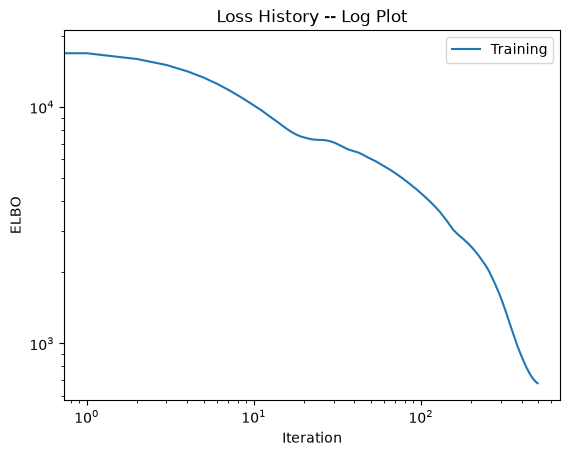

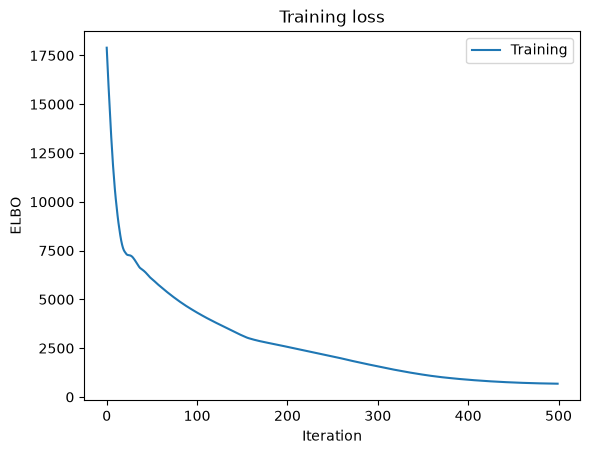

In [22]:
guide = AutoDelta(hsmodel)
lr = 5e-4
niter = 500
num_samples = 1

optimizer = ClippedAdam({"lr": lr})
loss = Trace_ELBO(num_particles=num_samples)
svi = SVI(hsmodel, guide, optimizer, loss=loss)

titer = tqdm.tqdm(
    range(niter),
    bar_format="{desc}: {percentage:3.0f}%|{bar}|{n_fmt}/{total_fmt}{postfix}",
)
titer.set_description("Loss:")
best_loss = float("inf")
best_state: dict | None = None
best_iter = -1
n_fail = 0
loss_history: list[float] = []

for i in titer:
    try:
        with ObsSiteMask(obs_mask, scale=obs_weight):
            closs = svi.step(loading, time, temperature, results=obs_stress)
    except RuntimeError as e:
        if "Implicit solve did not succeed" not in str(e):
            raise
        n_fail += 1
        titer.set_postfix(fails=n_fail, best=f"{best_loss:.2e}")
        continue

    if not math.isfinite(closs):
        n_fail += 1
        continue

    loss_history.append(closs)
    titer.set_description("Loss: %3.2e" % closs)

    if closs < best_loss:
        best_loss, best_iter = closs, i
        best_state = copy.deepcopy(pyro.get_param_store().get_state())

if best_state is None:
    raise RuntimeError("No successful training step; nothing to restore.")

pyro.get_param_store().set_state(best_state)
print(f"Restored iteration {best_iter}, loss {best_loss:.3e}")

plt.figure()
plt.loglog(loss_history, label="Training")
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.legend(loc="best")
plt.title("Loss History -- Log Plot")

plt.figure()
plt.plot(loss_history, label="Training")
plt.xlabel("Iteration")
plt.ylabel("ELBO")
plt.legend(loc="best")
plt.title("Training loss")
plt.show()

In [23]:
nreps = 10
predict = Predictive(hsmodel, guide=guide, num_samples=nreps)
with torch.no_grad():
    trained = predict(loading, time, temperature)["obs"]

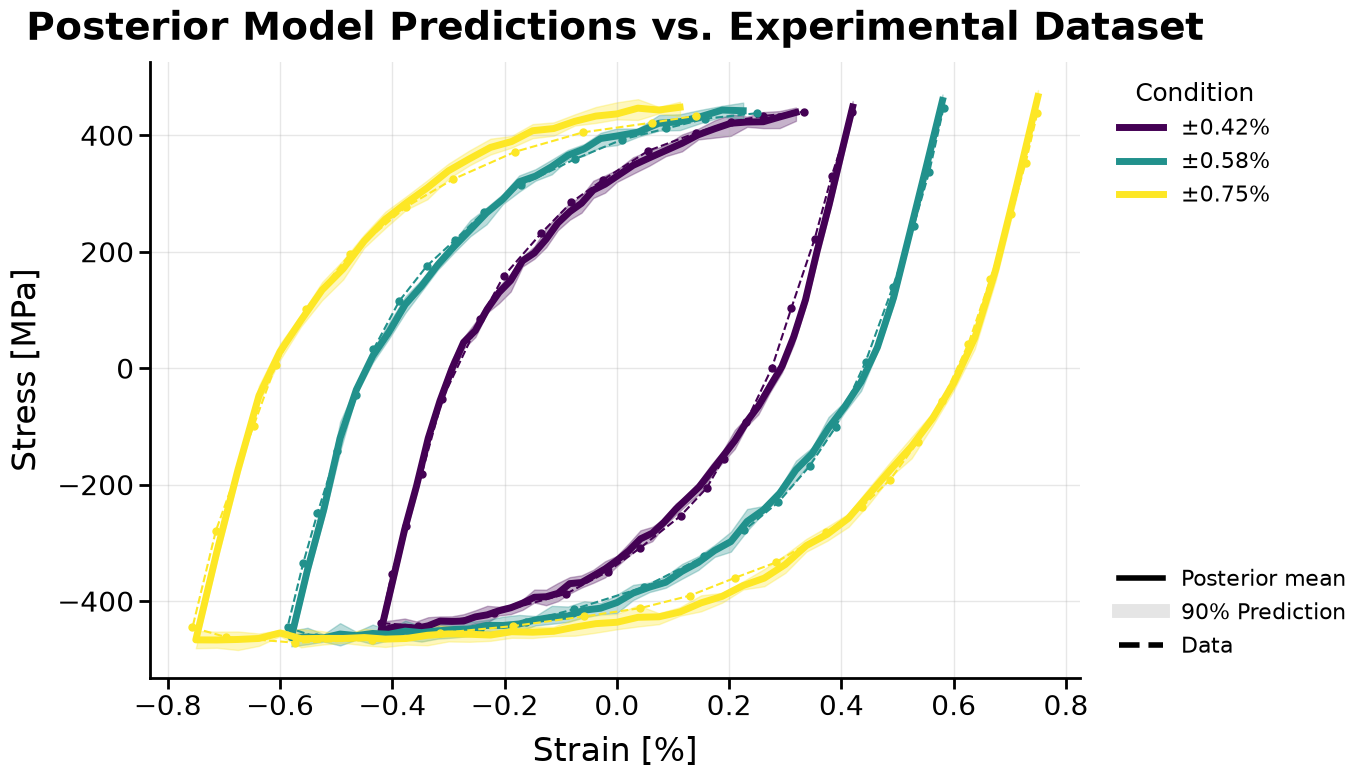

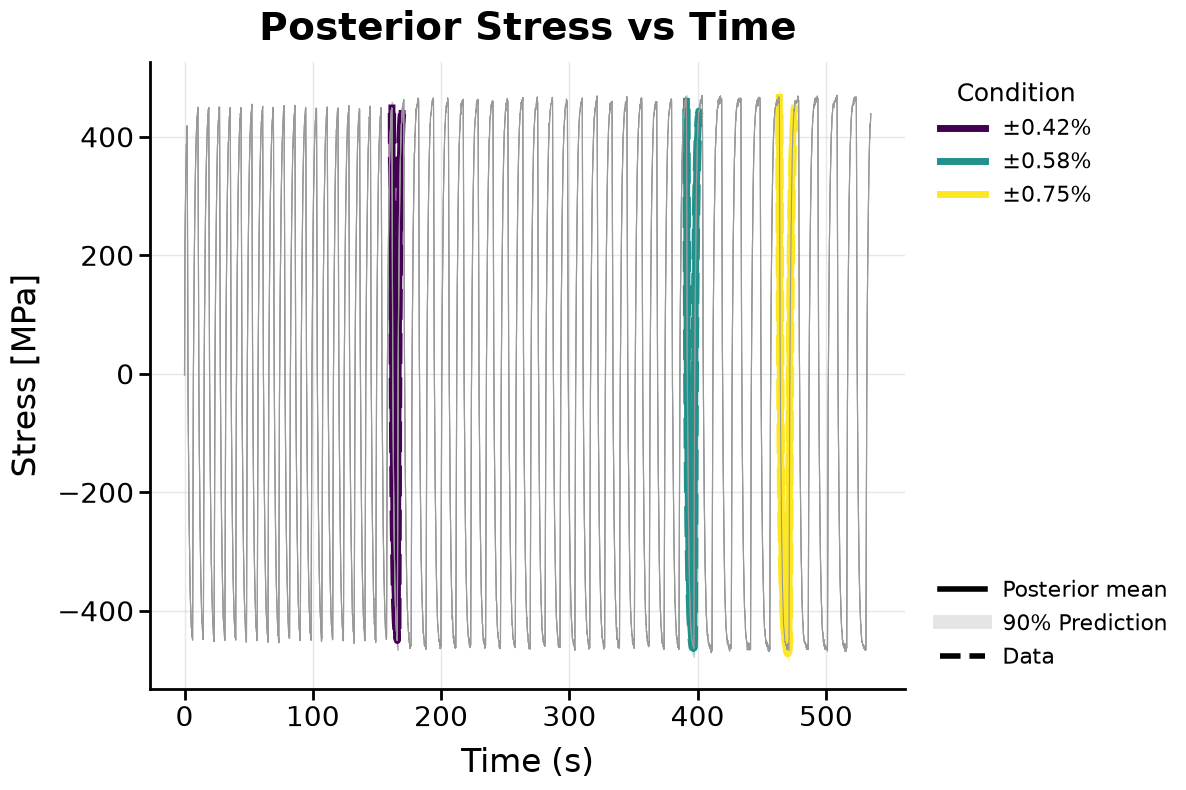

In [24]:
color = mpl.cm.viridis(np.linspace(0, 1, len(amp_labels)))
fig, ax = plt.subplots(figsize=(12, 8))

for j, label in enumerate(amp_labels):
    post_loop_stress = trained[:, compare_idx[j], 0, 0]
    eps = strain_history[compare_idx[j]].cpu().numpy() * 100
    ax.plot(
        eps,
        post_loop_stress.mean(axis=0).cpu(),
        color=color[j],
        lw=5,
    )
    lo, hi = torch.quantile(post_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax.fill_between(
        eps,
        lo.cpu(),
        hi.cpu(),
        color=color[j],
        alpha=0.3,
    )
    ax.plot(
        loop_strain[label].cpu().numpy() * 100,
        loop_stress[label].cpu().numpy(),
        "--o",
        ms=5,
        color=color[j],
    )
# Legend: one colored entry per test condition, plus line-style key for Model vs Data
cond_handles = [
    Line2D(
        [0],
        [0],
        color=color[j],
        lw=5,
        label=rf"$\pm${amp}%",
    )
    for j, amp in enumerate(amp_labels)
]
style_handles = [
    Line2D([0], [0], color="k", lw=4, label="Posterior mean"),
    Line2D([], [], color="0.8", alpha=0.5, lw=10, label="90% Prediction"),
    Line2D([0], [0], color="k", lw=4, ls="--", label="Data"),
]
leg_cond = ax.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax.add_artist(leg_cond)
ax.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)

ax.set_xlabel("Strain [%]", fontsize=24, labelpad=10)
ax.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax.set_title(
    "Posterior Model Predictions vs. Experimental Dataset", fontsize=28, fontweight="bold", pad=16
)
ax.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_linewidth(2)

t = time_history.cpu().numpy()
fig, ax1 = plt.subplots(figsize=(12, 8))
for j, label in enumerate(amp_labels):
    idx = compare_idx[j].cpu()
    post_loop_stress = trained[:, compare_idx[j], 0, 0]
    lo, hi = torch.quantile(post_loop_stress, torch.tensor([0.05, 0.95], device=device), dim=0)
    ax1.plot(t[idx], post_loop_stress.mean(dim=0).detach().cpu().numpy(), color=color[j], lw=5)
    ax1.fill_between(t[idx], lo.cpu().numpy(), hi.cpu().numpy(), color=color[j], alpha=0.3)
    ax1.plot(t[idx], targets[j].cpu().numpy(), "--", color=color[j], lw=6)
    ax1.plot(t, trained[:, :, 0, 0].mean(dim=0).cpu().numpy(), color="0.6", lw=0.8)
leg_cond = ax1.legend(
    handles=cond_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=16,
    title="Condition",
    title_fontsize=18,
    frameon=False,
)
ax1.add_artist(leg_cond)
ax1.legend(
    handles=style_handles,
    loc="lower left",
    bbox_to_anchor=(1.02, 0.0),
    fontsize=16,
    frameon=False,
)
ax1.set_xlabel("Time (s)", fontsize=24, labelpad=10)
ax1.set_ylabel("Stress [MPa]", fontsize=24, labelpad=10)
ax1.set_title("Posterior Stress vs Time", fontsize=28, fontweight="bold", pad=16)
ax1.tick_params(axis="both", which="major", labelsize=20, width=2, length=8)
ax1.grid(True, alpha=0.3, lw=1)
for spine in ("top", "right"):
    ax1.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax1.spines[spine].set_linewidth(2)
plt.tight_layout()
plt.show()

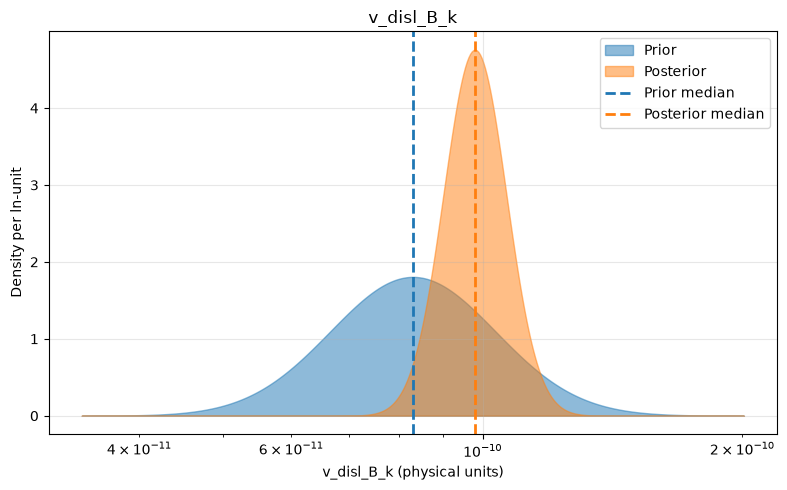

v_disl_B_k: loc = 8.300e-11, scale = 1.247
v_disl_B_k: loc = 9.795e-11, scale = 1.087


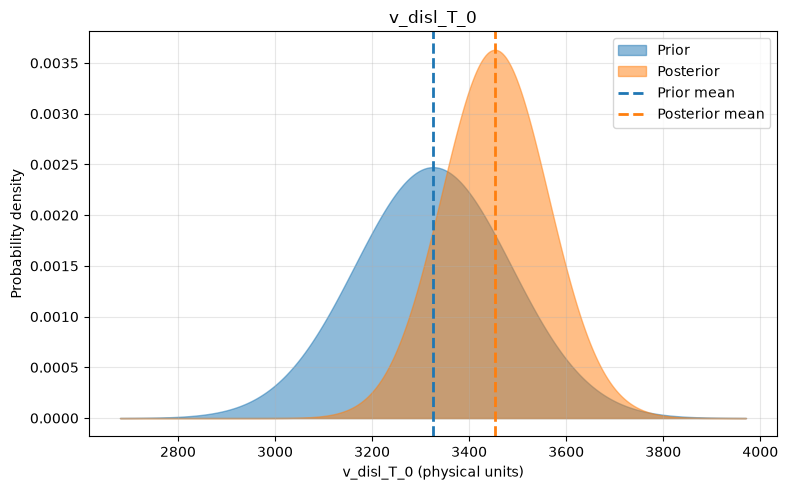

v_disl_T_0: loc = 3325.500, scale = 161.275
v_disl_T_0: loc = 3452.891, scale = 109.887


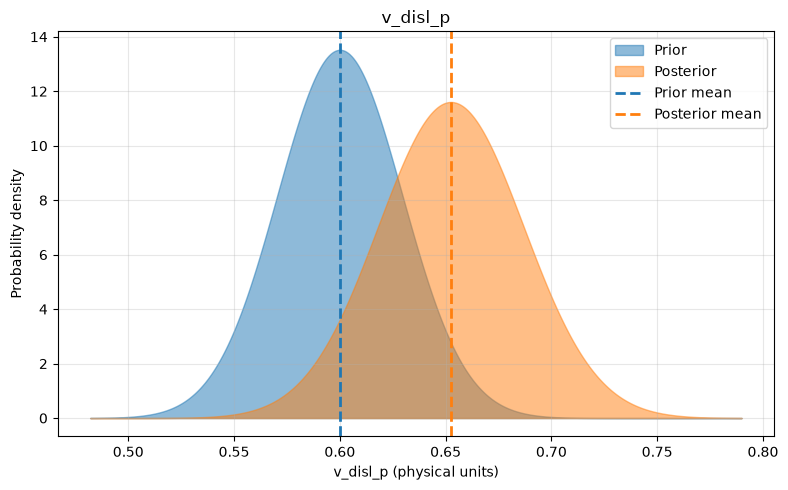

v_disl_p: loc = 0.600, scale = 0.030
v_disl_p: loc = 0.652, scale = 0.034


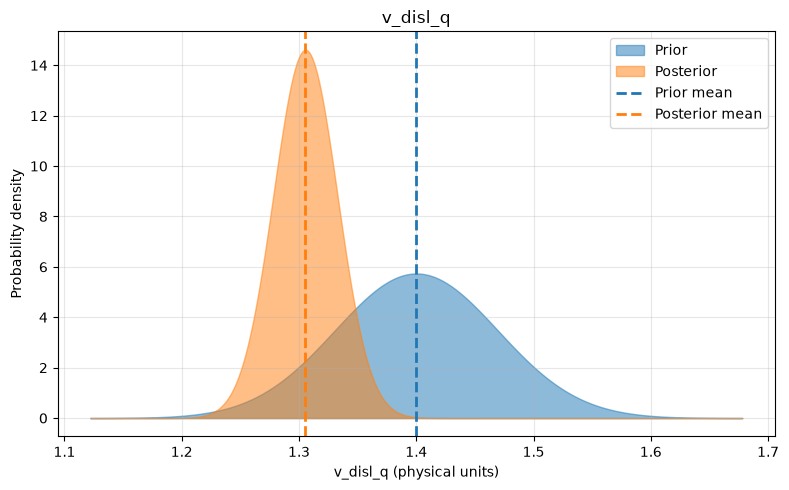

v_disl_q: loc = 1.400, scale = 0.069
v_disl_q: loc = 1.305, scale = 0.027


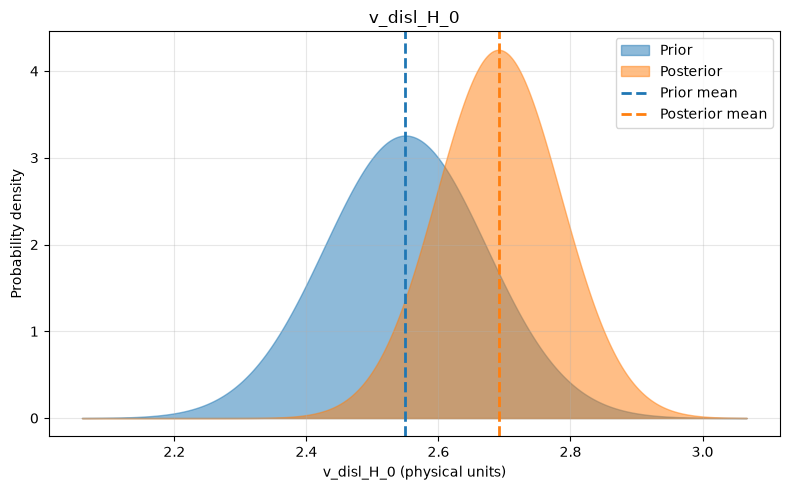

v_disl_H_0: loc = 2.550, scale = 0.122
v_disl_H_0: loc = 2.691, scale = 0.094


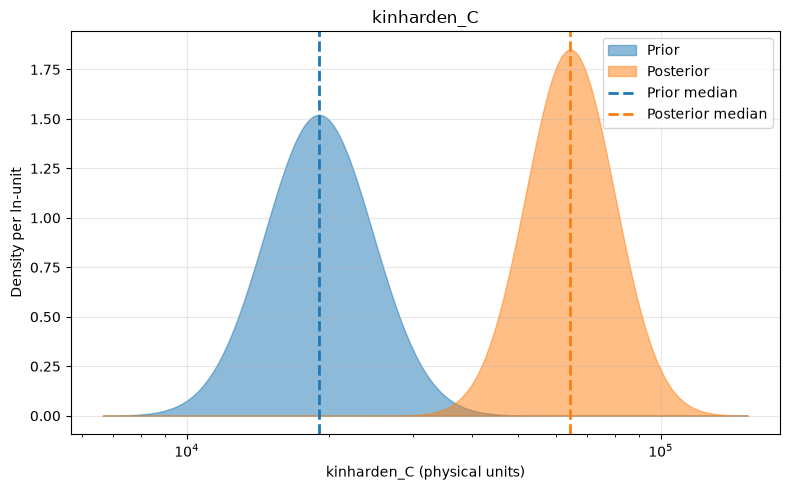

kinharden_C: loc = 19000.000, scale = 1.300
kinharden_C: loc = 64404.929, scale = 1.241


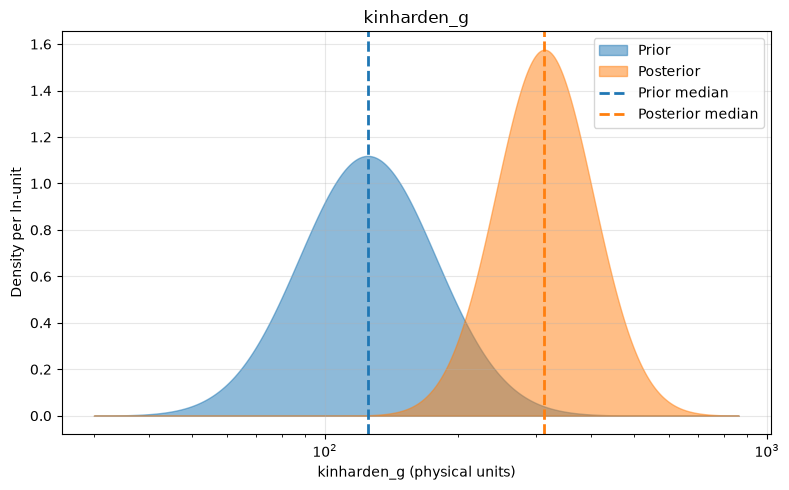

kinharden_g: loc = 125.000, scale = 1.428
kinharden_g: loc = 313.768, scale = 1.288


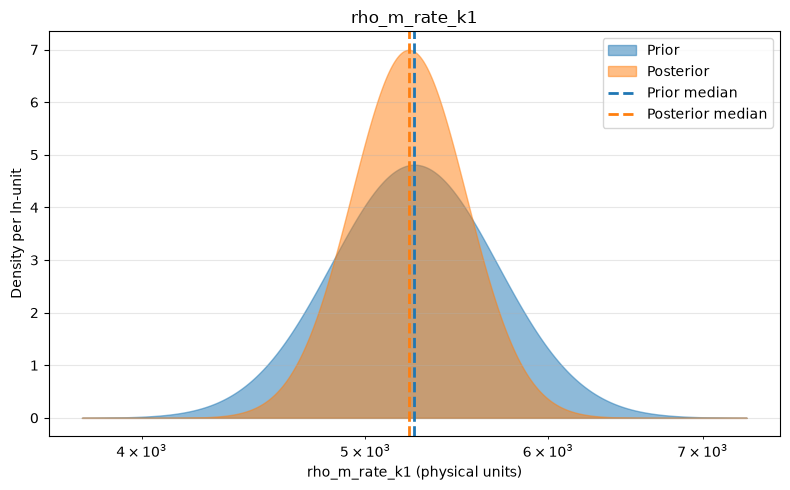

rho_m_rate_k1: loc = 5250.000, scale = 1.086
rho_m_rate_k1: loc = 5221.290, scale = 1.059


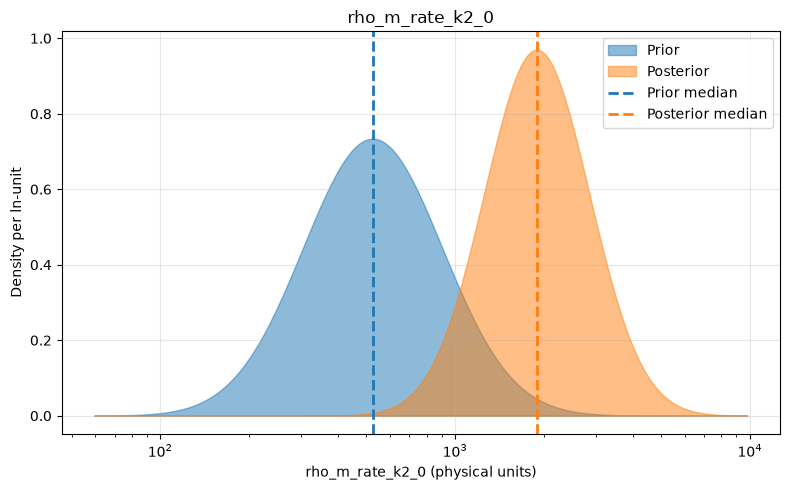

rho_m_rate_k2_0: loc = 525.000, scale = 1.722
rho_m_rate_k2_0: loc = 1891.095, scale = 1.509


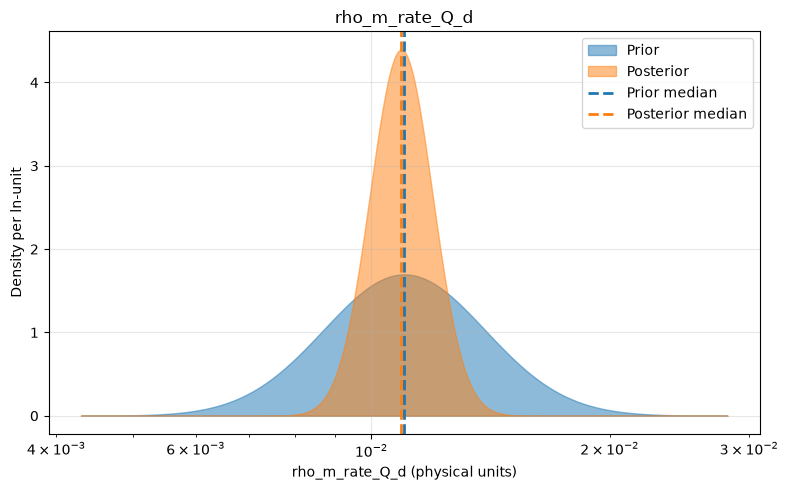

rho_m_rate_Q_d: loc = 0.011, scale = 1.265
rho_m_rate_Q_d: loc = 0.011, scale = 1.095


In [25]:
def scaled_to_physical(scaler, mu, sigma):
    lb, ub = float(scaler.lb), float(scaler.ub)
    return lb + float(mu) * (ub - lb), float(sigma) * abs(ub - lb)


for _, _, n in hsmodel.bot:
    key = ".".join(n.split(".")[i] for i in [0, 2])
    scaler = model_reparameterizer.map_dict[key]
    param_name = key.split(".")[-1]
    is_log = isinstance(scaler, LogRangeRescale)

    # Scaled-space (z) normals
    prior_loc = initial_params_reparam[n]
    prior_scale = prior_cov * prior_loc.abs()
    post_loc = pyro.param(f"AutoDelta.{n}_loc").detach()
    post_scale = pyro.param(f"AutoDelta.{n}_scale").detach()

    # Physical-space normals (in u = theta or ln(theta))
    mu_prior, sigma_prior = scaled_to_physical(scaler, prior_loc, prior_scale)
    mu_post, sigma_post = scaled_to_physical(scaler, post_loc, post_scale)

    # Common grid covering both distribution, limited to the clamp bounds [lb, ub]
    lo = max(min(mu_prior - 4 * sigma_prior, mu_post - 4 * sigma_post), float(scaler.lb))
    hi = min(max(mu_prior + 4 * sigma_prior, mu_post + 4 * sigma_post), float(scaler.ub))
    u = torch.linspace(lo, hi, 400, device=device)

    y_prior = dist.Normal(mu_prior, sigma_prior).log_prob(u).exp()
    y_post = dist.Normal(mu_post, sigma_post).log_prob(u).exp()
    x = u.exp() if is_log else u
    to_x = math.exp if is_log else (lambda v: v)

    plt.figure(figsize=(8, 5))
    plt.fill_between(x.cpu(), y_prior.cpu(), alpha=0.5, color="C0", label="Prior")
    plt.fill_between(x.cpu(), y_post.cpu(), alpha=0.5, color="C1", label="Posterior")
    stat = "median" if is_log else "mean"
    plt.axvline(to_x(mu_prior), color="C0", ls="--", lw=2, label=f"Prior {stat}")
    plt.axvline(to_x(mu_post), color="C1", ls="--", lw=2, label=f"Posterior {stat}")

    if is_log:
        plt.xscale("log")
    plt.xlabel(f"{param_name} (physical units)")
    plt.ylabel("Density per ln-unit" if is_log else "Probability density")
    plt.title(param_name)
    plt.legend(loc="best")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    if param_name == "v_disl_B_k":
        print(rf"{param_name}: loc = {to_x(mu_prior):.3e}, scale = {to_x(sigma_prior):.3f}")
        print(rf"{param_name}: loc = {to_x(mu_post):.3e}, scale = {to_x(sigma_post):.3f}")
    else:
        print(rf"{param_name}: loc = {to_x(mu_prior):.3f}, scale = {to_x(sigma_prior):.3f}")
        print(rf"{param_name}: loc = {to_x(mu_post):.3f}, scale = {to_x(sigma_post):.3f}")

In [31]:
import pickle, pathlib

out_dir = pathlib.Path("../figures/data")
out_dir.mkdir(parents=True, exist_ok=True)


def to_np(x):
    return x.detach().cpu().numpy()


q = torch.tensor([0.05, 0.95], device=device)

curves = []
for j, amp in enumerate(amp_labels):
    idx = compare_idx[j]
    samples = trained[:, idx, 0, 0]  # (nreps, ntime)
    prior_samples = untrained[:, idx, 0, 0]
    lo, hi = torch.quantile(samples, q, dim=0)
    plo, phi = torch.quantile(prior_samples, q, dim=0)
    curves.append(
        {
            "label": rf"$\pm${amp}%",
            "T": temperature_K,
            "rate": strain_rate,
            "amplitudes": amplitudes[j],
            "compare_cycle": compare_cycle[j],
            "loss_weight": loss_weights[j],
            "model_strain": to_np(strain_history[idx]),
            "model_time": to_np(time_history[idx]),
            "model_stress_mean": to_np(samples.mean(dim=0)),
            "model_stress_lo": to_np(lo),  # 5% quantile
            "model_stress_hi": to_np(hi),  # 95% quantile
            "model_stress_samples": to_np(samples),
            "prior_stress_mean": to_np(prior_samples.mean(dim=0)),
            "prior_stress_lo": to_np(plo),
            "prior_stress_hi": to_np(phi),
            "exp_strain": to_np(loop_strain[amp]),
            "exp_stress": to_np(loop_stress[amp]),
            "exp_target_strain": to_np(target_strain[j]),
            "exp_target_stress": to_np(targets[j]),
        }
    )
# Full MST history, for the gray background trace
full = trained[:, :, 0, 0]
full_lo, full_hi = torch.quantile(full, q, dim=0)
background = {
    "time": to_np(time_history),
    "strain": to_np(strain_history),
    "stress_mean": to_np(full.mean(dim=0)),
    "stress_lo": to_np(full_lo),
    "stress_hi": to_np(full_hi),
    "prior_stress_mean": to_np(untrained[:, :, 0, 0].mean(dim=0)),
}

# Prior/posterior parameter distributions in physical space (same math as the last cell)
params = {}
for _, _, n in hsmodel.bot:
    key = ".".join(n.split(".")[k] for k in [0, 2])
    scaler = model_reparameterizer.map_dict[key]
    prior_loc = initial_params_reparam[n]
    mu_prior, sigma_prior = scaled_to_physical(scaler, prior_loc, prior_cov * prior_loc.abs())
    mu_post, sigma_post = scaled_to_physical(
        scaler,
        pyro.param(f"AutoDelta.{n}_loc").detach(),
        pyro.param(f"AutoDelta.{n}_scale").detach(),
    )
    params[key.split(".")[-1]] = {
        "is_log": is_log,
        "space": "ln" if is_log else "linear",
        "lb": float(scaler.lb),
        "ub": float(scaler.ub),
        "prior": (mu_prior, sigma_prior),
        "posterior": (mu_post, sigma_post),
    }

case = {
    "material": "tungsten",
    "loading": "cyclic",
    "approach": "statistical",
    "quantiles": (0.05, 0.95),
    "nreps": nreps,
    "band_includes_noise": True,
    "noise_scale": pyro.param("AutoDelta.eps").item(),
    "curves": curves,
    "background": background,
    "params": params,
    "loss_history": [float(l) for l in loss_history],
    "best_iter": best_iter,
    "best_loss": best_loss,
    "n_fail": n_fail,
    "settings": {
        "prior_cov": prior_cov,
        "prior_noise_scale": prior_noise_scale,
        "lr": lr,
        "niter": niter,
        "temperature_K": temperature_K,
        "strain_rate": strain_rate,
        "amplitudes": amplitudes,
        "n_cycles": n_cycles,
        "compare_cycle": compare_cycle,
        "loss_weights": loss_weights,
        "points_per_cycle": points_per_cycle,
        "ntime": ntime,
        "nchunk": model.nchunk,
        "initial_rho_m": model.initial_rho_m,
    },
}

out_path = out_dir / "cyclic_tungsten_statistical.pkl"
with open(out_path, "wb") as f:
    pickle.dump(case, f)
print(f"Saved {out_path.resolve()}")
print(f"Learned noise scale: {case['noise_scale']:.1f} MPa")

Saved /Users/quantumsurfer/neml2/cmg_projects/figures/data/cyclic_tungsten_statistical.pkl
Learned noise scale: 9.7 MPa
